<a href="https://colab.research.google.com/github/adityaDev-2005/Satellite-Image-Analysis-for-land-cover-Data-processing-Training-/blob/main/Satellite_Image_Analysis_Error_Analysis(River_%3E_Highway).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing necessary libraries

In [1]:
import os

print("Current directory:", os.getcwd())
print("Model path:", os.path.abspath("eurosat_cnn.pth"))
print("Model exists:", os.path.exists("eurosat_cnn.pth"))

Current directory: /content
Model path: /content/eurosat_cnn.pth
Model exists: False


In [2]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from torch.utils.data import Dataset, DataLoader
from torchvision.io import decode_image
from torchvision import transforms

from sklearn.metrics import confusion_matrix, classification_report

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cpu


Dataset Class

In [4]:
from torch.utils.data import Dataset
import pandas as pd
from torchvision.io import decode_image
import os

class EuroSATDataset(Dataset):
  def __init__(self,annotations_file,img_dir,transform=None,target_transform=None):
    self.img_labels = pd.read_csv(annotations_file)
    self.img_dir = img_dir
    self.transform = transform
    self.target_transform = target_transform

  def __len__(self):
    return len(self.img_labels)


  def __getitem__(self,idx):
    img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx,1])
    image = decode_image(img_path)
    label = self.img_labels.iloc[idx,2]
    if self.transform:
      image = self.transform(image)
    if self.target_transform:
      label = self.target_transform(label)
    return image,label



In [5]:
transform = transforms.Compose([
    transforms.ConvertImageDtype(torch.float32)
])

In [6]:
import kagglehub

path = kagglehub.dataset_download("apollo2506/eurosat-dataset")

dataset_path = os.path.join(path, "EuroSAT")

print("Dataset path:", dataset_path)

Using Colab cache for faster access to the 'eurosat-dataset' dataset.
Dataset path: /kaggle/input/eurosat-dataset/EuroSAT


In [7]:
val_dataset = EuroSATDataset(
    annotations_file=os.path.join(dataset_path, "validation.csv"),
    img_dir=dataset_path,
    transform=transform
)

print("Validation samples:", len(val_dataset))

Validation samples: 5400


In [8]:
val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Validation batches:", len(val_loader))

Validation batches: 169


Loading the pre-trained model

In [9]:
class EuroSATCNN(nn.Module):
  def __init__(self):
    super(EuroSATCNN,self).__init__()

    self.conv1 = nn.Conv2d(in_channels=3,out_channels=16,kernel_size=3)
    self.conv2 = nn.Conv2d(in_channels=16,out_channels=32,kernel_size=3)
    self.activation = nn.ReLU()

    # first fully-connected layer
    self.fc1 = nn.Linear(in_features=6272,out_features=128)

    # final classfication layer
    self.fc2 = nn.Linear(in_features=128,out_features=10)

  def forward(self,x):
    # 1st convolution
    x = self.conv1(x)
    x = self.activation(x)

    # pooling
    x = F.max_pool2d(x,kernel_size=(2,2))

    # 2nd convolution
    x = self.conv2(x)
    x = self.activation(x)

    # pooling
    x = F.max_pool2d(x,kernel_size=(2,2))

    x = torch.flatten(x,start_dim=1)

    # fully conencted layer
    x = self.fc1(x)

    x = self.activation(x)

    x = self.fc2(x)

    return x

model = EuroSATCNN()
print(model)

params = list(model.parameters())


x = torch.randn(32, 3, 64, 64)
output = model(x)
print(output.shape)



# x = torch.randn(32, 3, 64, 64)
# print(x.shape)


EuroSATCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1))
  (activation): ReLU()
  (fc1): Linear(in_features=6272, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
torch.Size([32, 10])


In [10]:
import os

model_path = "/eurosat_cnn.pth"

print("File exists:", os.path.exists(model_path))

File exists: False


In [14]:
model_path = "/content/eurosat_cnn.pth"

model = EuroSATCNN().to(device)

model.load_state_dict(
    torch.load(
        model_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Trained model loaded successfully!")

Trained model loaded successfully!


In [15]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Total predictions:", len(all_predictions))
print("Total labels:", len(all_labels))

Total predictions: 5400
Total labels: 5400


In [17]:
class_names = (
    val_dataset.img_labels
    .drop_duplicates("Label")
    .sort_values("Label")["ClassName"]
    .tolist()
)

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(10))
)

print(cm)

[[499   3  12  13   0  29  24   0  10  10]
 [  0 553   3   0   0  40   0   0   2   2]
 [  4  10 462  22   9  10  66  10   5   2]
 [ 13   0  27 355   9  14  31  10  41   0]
 [  0   0   7  25 448   0   5  12   3   0]
 [  7   3  16  12   0 337  18   0   7   0]
 [ 30   1  64  46   4   9 331   1  14   0]
 [  0   0  23  10  25   0   0 542   0   0]
 [ 14   9  25 126   0  23  11   0 291   1]
 [  7  17   1   1   0  19   0   0   4 551]]


Displaying the Confusion Matrix using heatmap

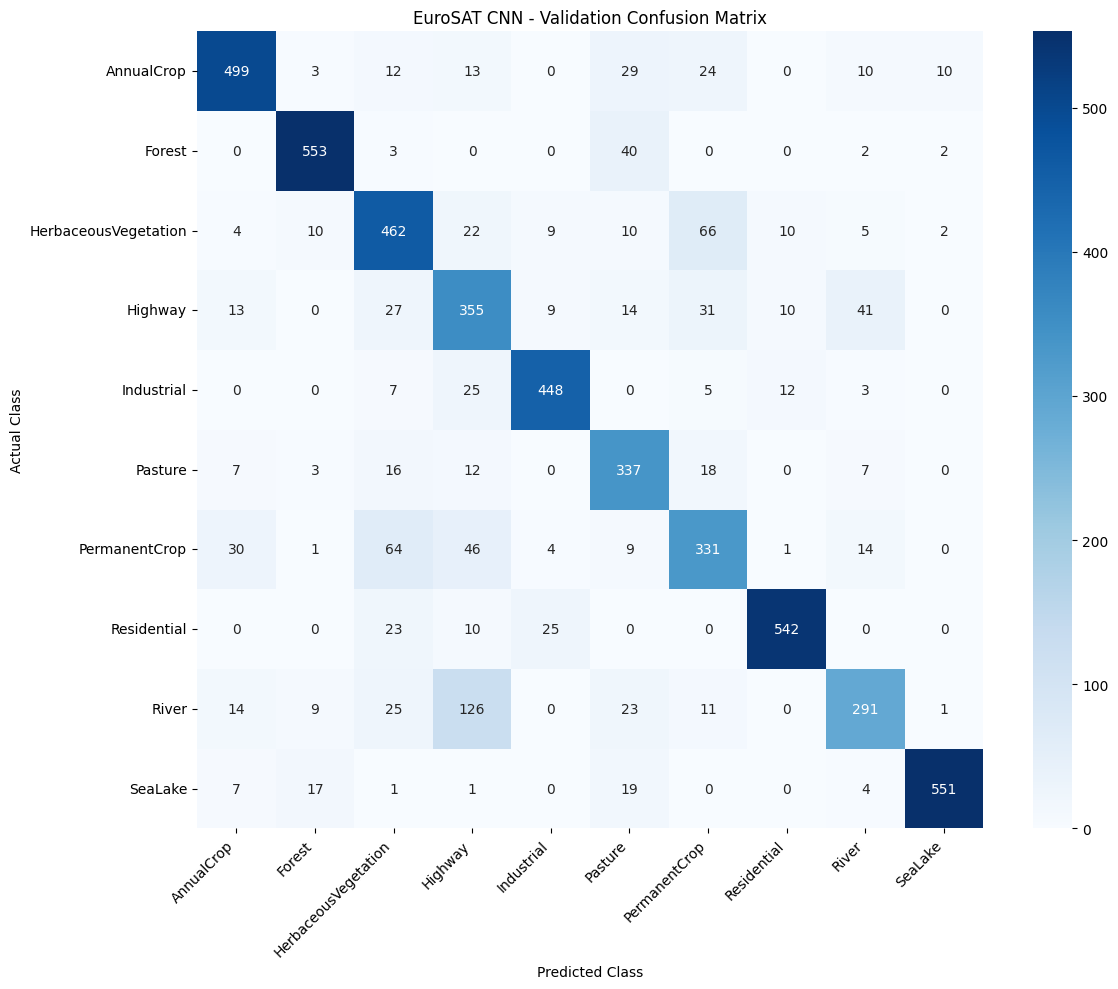

In [18]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("EuroSAT CNN - Validation Confusion Matrix")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Classification Report

In [19]:
print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4
))

                      precision    recall  f1-score   support

          AnnualCrop     0.8693    0.8317    0.8501       600
              Forest     0.9279    0.9217    0.9247       600
HerbaceousVegetation     0.7219    0.7700    0.7452       600
             Highway     0.5820    0.7100    0.6396       500
          Industrial     0.9051    0.8960    0.9005       500
             Pasture     0.7006    0.8425    0.7650       400
       PermanentCrop     0.6811    0.6620    0.6714       500
         Residential     0.9426    0.9033    0.9226       600
               River     0.7719    0.5820    0.6636       500
             SeaLake     0.9735    0.9183    0.9451       600

            accuracy                         0.8091      5400
           macro avg     0.8076    0.8037    0.8028      5400
        weighted avg     0.8169    0.8091    0.8104      5400



Displaying the incorrectly classified images

In [20]:
misclassified_images = []
misclassified_actual = []
misclassified_predicted = []
misclassified_dataset_indices = []

model.eval()

with torch.no_grad():

    for batch_index, (images, labels) in enumerate(val_loader):

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        wrong_indices = (
            (predictions != labels.to(device))
            .nonzero(as_tuple=True)[0]
        )

        for idx in wrong_indices:

            original_idx = batch_index * 32 + idx.item()

            misclassified_images.append(images[idx].cpu())
            misclassified_actual.append(labels[idx].item())
            misclassified_predicted.append(predictions[idx].item())
            misclassified_dataset_indices.append(original_idx)

In [21]:
print(len(misclassified_images))
print(len(misclassified_dataset_indices))

1031
1031


In [26]:
river_highway_indices = [
    misclassified_dataset_indices[i]
    for i in pair_indices
]

It converts the 126 positions in the misclassified list into their corresponding original dataset positions.

In [27]:
print(len(river_highway_indices))

126


Retrieving the first image of the misclassified river image

In [28]:
idx = river_highway_indices[0]

image, label = val_dataset[idx]

Displaying it

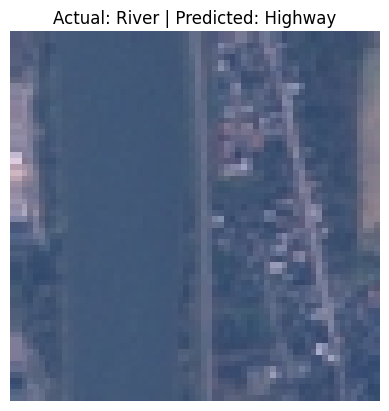

In [29]:
plt.imshow(image.permute(1, 2, 0))
plt.title("Actual: River | Predicted: Highway")
plt.axis("off")
plt.show()

In [30]:
print("Shape:", image.shape)
print("Data type:", image.dtype)
print("Minimum:", image.min().item())
print("Maximum:", image.max().item())

Shape: torch.Size([3, 64, 64])
Data type: torch.float32
Minimum: 0.1882352977991104
Maximum: 0.8745098114013672


Displaying the color channels of the image in grayscale

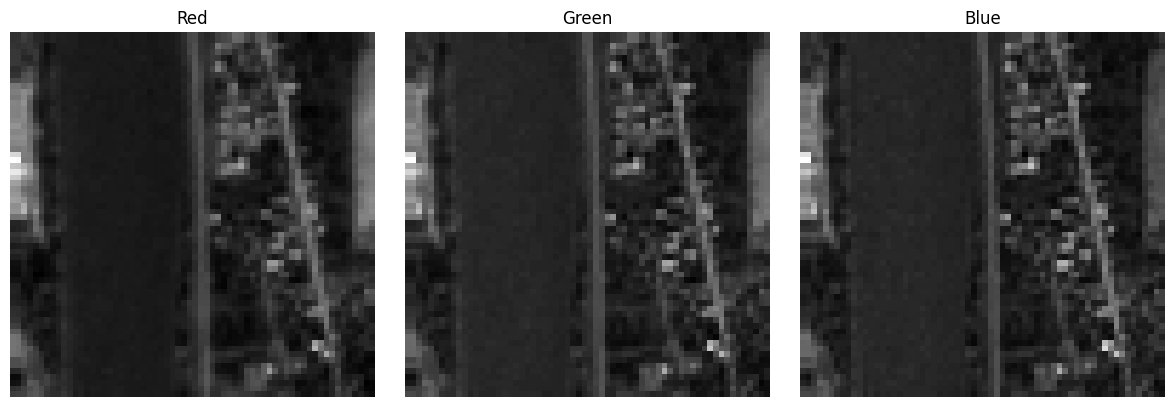

In [31]:
plt.figure(figsize=(12, 4))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(image[i], cmap='gray')
    plt.title(["Red", "Green", "Blue"][i])
    plt.axis("off")

plt.tight_layout()
plt.show()

: -> selects all the 3 color channels, 20 -> selects row 20, 20 -> selects column 20

In [32]:
print("Pixel at (20, 20):", image[:, 20, 20])
print("Pixel at (30, 30):", image[:, 30, 30])
print("Pixel at (40, 40):", image[:, 40, 40])

Pixel at (20, 20): tensor([0.2510, 0.3412, 0.4627])
Pixel at (30, 30): tensor([0.2431, 0.3255, 0.4471])
Pixel at (40, 40): tensor([0.2588, 0.3333, 0.4588])


Displaying the image as grid to get the row and column values

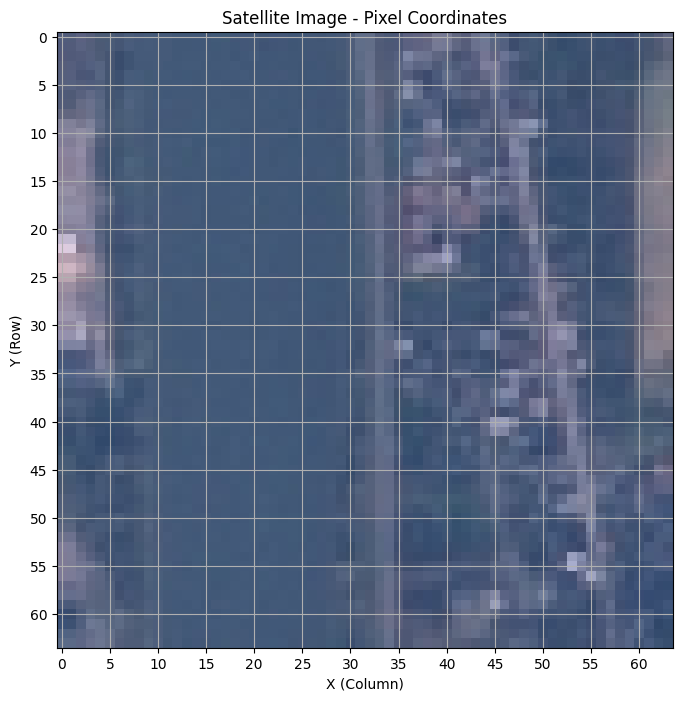

In [33]:
plt.figure(figsize=(8, 8))

plt.imshow(image.permute(1, 2, 0))

plt.xticks(range(0, 64, 5))
plt.yticks(range(0, 64, 5))

plt.grid()
plt.xlabel("X (Column)")
plt.ylabel("Y (Row)")
plt.title("Satellite Image - Pixel Coordinates")

plt.show()

In [34]:
print("Pixel inside river(Actual river):", image[:, 20, 20])
print("Pixel outside river(land part):", image[:, 50, 50])

Pixel inside river(Actual river): tensor([0.2510, 0.3412, 0.4627])
Pixel outside river(land part): tensor([0.2745, 0.3529, 0.4824])


In [35]:
river_region = image[:, 10:30, 10:25]
river_region.shape

torch.Size([3, 20, 15])

In [36]:
river_mean = river_region.mean(dim=(1,2))
print(river_mean)
print(river_mean.shape)

tensor([0.2576, 0.3475, 0.4698])
torch.Size([3])


In [37]:
land_region = image[:, 30:60, 40:55]

land_mean = land_region.mean(dim=(1, 2))

print(land_mean)
print(land_mean.shape)

tensor([0.3225, 0.3759, 0.4979])
torch.Size([3])


In [38]:
river_brightness = river_mean.mean()
land_brightness = land_mean.mean()

print("River brightness:", river_brightness.item())
print("Land brightness:", land_brightness.item())

River brightness: 0.3582700788974762
Land brightness: 0.3987480103969574


Finding the brightness average for all of the misclassified images

In [39]:
misclassified_brightness = []

for idx in river_highway_indices:

    image, label = val_dataset[idx]

    brightness = image.mean().item()

    misclassified_brightness.append(brightness)

In [40]:
print(len(misclassified_brightness))

126


In [41]:
average_misclassified_brightness = sum(misclassified_brightness) / len(misclassified_brightness)
print(average_misclassified_brightness)

0.33865750758420854


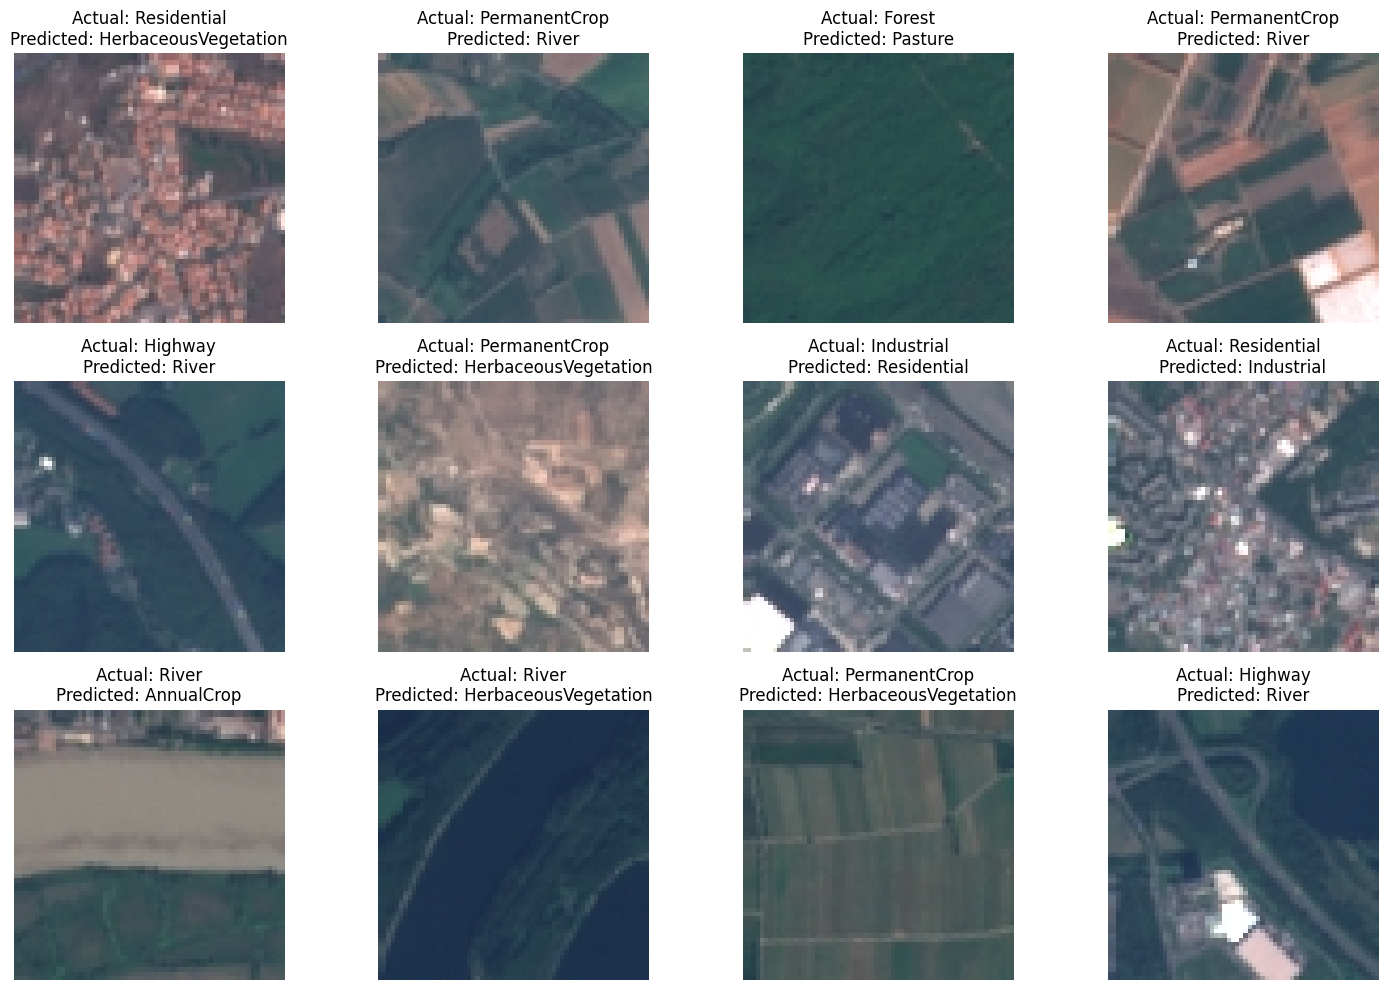

In [42]:
plt.figure(figsize=(15, 10))

for i in range(min(12, len(misclassified_images))):

    image = misclassified_images[i].permute(1, 2, 0)

    actual = class_names[misclassified_actual[i]]
    predicted = class_names[misclassified_predicted[i]]

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Fixing the incorrect classes (To identify which classes are misclassified)

In [43]:
import pandas as pd

errors = []

for i in range(10):
    for j in range(10):

        if i != j and cm[i, j] > 0:

            errors.append({
                "Actual Class": class_names[i],
                "Predicted Class": class_names[j],
                "Misclassified Count": int(cm[i, j])
            })

errors_df = pd.DataFrame(errors)

errors_df = errors_df.sort_values(
    by="Misclassified Count",
    ascending=False
).reset_index(drop=True)

errors_df.head(10)


,Actual Class,Predicted Class,Misclassified Count
0,River,Highway,126
1,HerbaceousVegetation,PermanentCrop,66
2,PermanentCrop,HerbaceousVegetation,64
3,PermanentCrop,Highway,46
4,Highway,River,41
5,Forest,Pasture,40
6,Highway,PermanentCrop,31
7,PermanentCrop,AnnualCrop,30
8,AnnualCrop,Pasture,29
9,Highway,HerbaceousVegetation,27


Classwise error identify

In [44]:
class_errors = cm.sum(axis=1) - cm.diagonal()

for i,name in enumerate(class_names):
  print(f"{name} : {class_errors[i]} errors")


AnnualCrop : 101 errors
Forest : 47 errors
HerbaceousVegetation : 138 errors
Highway : 145 errors
Industrial : 52 errors
Pasture : 63 errors
PermanentCrop : 169 errors
Residential : 58 errors
River : 209 errors
SeaLake : 49 errors


Total Errors for each class in a proper dataframe

In [45]:
class_errors = cm.sum(axis=1) - cm.diagonal()

class_errors_df = pd.DataFrame({
    "Class": class_names,
    "Total Errors": class_errors
})

class_errors_df = class_errors_df.sort_values(
    by="Total Errors",
    ascending=False
).reset_index(drop=True)

class_errors_df

,Class,Total Errors
0,River,209
1,PermanentCrop,169
2,Highway,145
3,HerbaceousVegetation,138
4,AnnualCrop,101
5,Pasture,63
6,Residential,58
7,Industrial,52
8,SeaLake,49
9,Forest,47


Plotting the total errors of each class

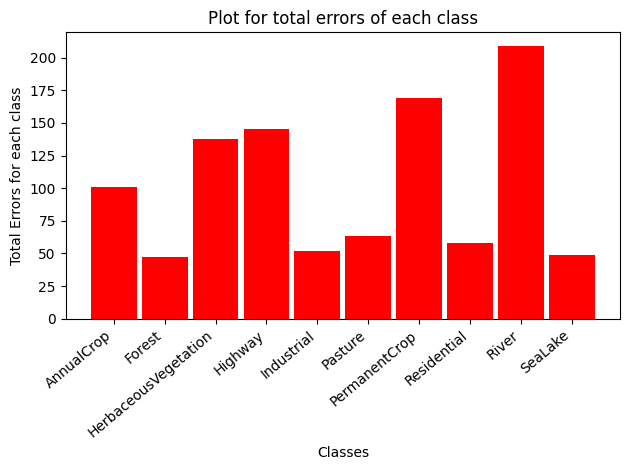

In [46]:
import matplotlib.pyplot as plt

plt.bar(class_names, class_errors, color='red',width=0.9)
plt.xlabel('Classes')
plt.ylabel('Total Errors for each class')
plt.title('Plot for total errors of each class')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

Inspecting the most errors pair i.e. River and Highway

In [24]:
target_actual = class_names.index('River')
target_predicted = class_names.index('Highway')

In [25]:
pair_indices = []

for i in range(len(misclassified_actual)):
    if (misclassified_actual[i] == target_actual and
        misclassified_predicted[i] == target_predicted):

        pair_indices.append(i)

print("Number of River → Highway errors:", len(pair_indices))

Number of River → Highway errors: 126


Displaying the first 12 River-Highway mislclassified images from total 126 images

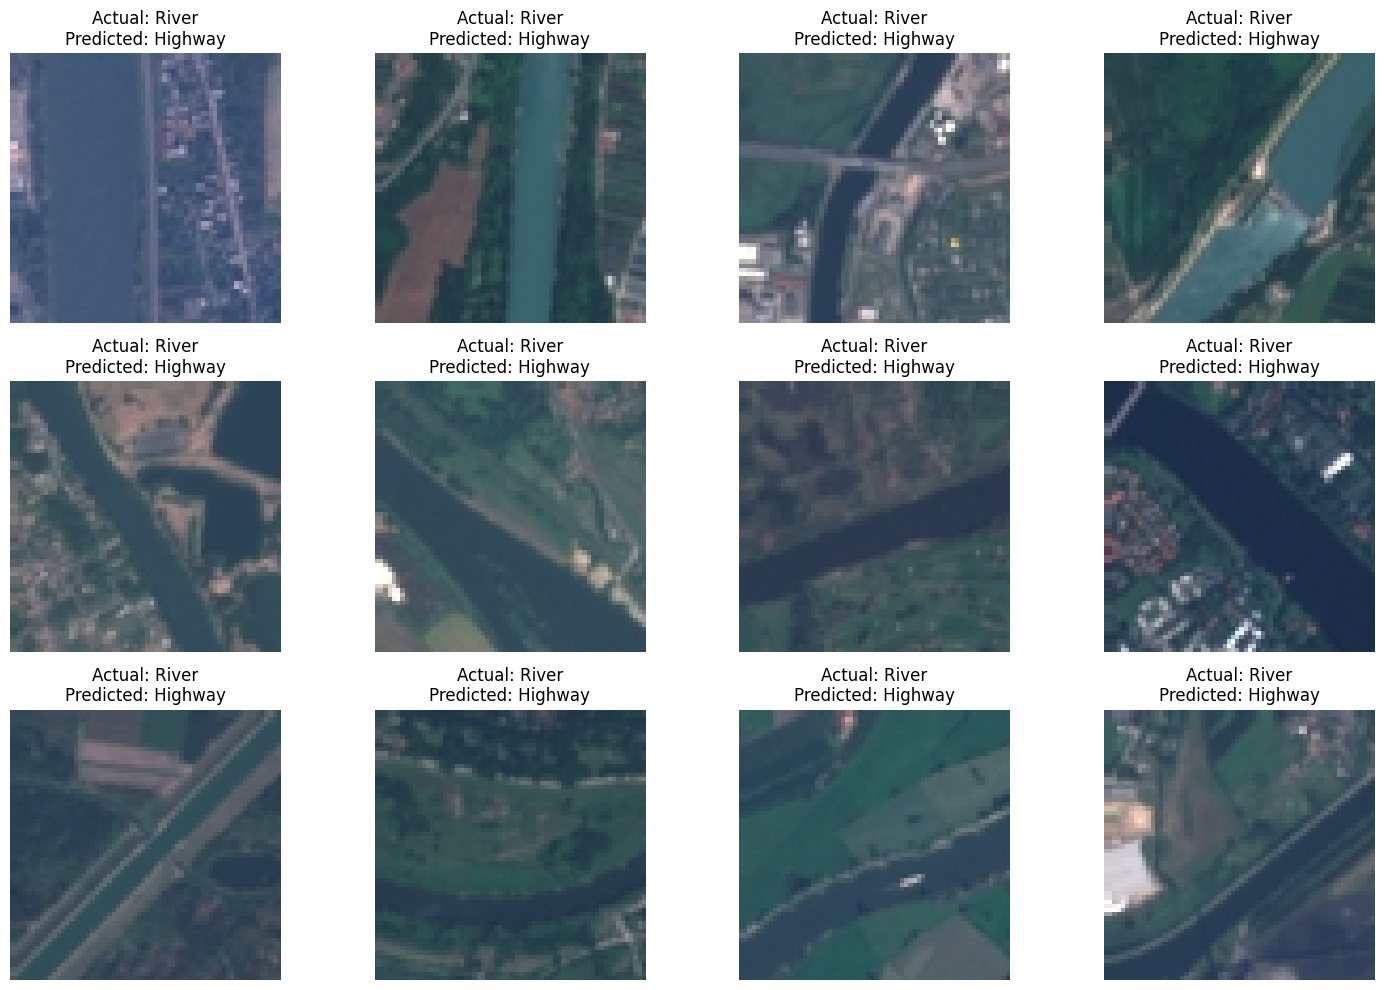

In [47]:
plt.figure(figsize=(15, 10))

for i in range(min(12, len(misclassified_images))):

    image = misclassified_images[pair_indices[i]].permute(1, 2, 0)

    idx = pair_indices[i]

    actual = class_names[misclassified_actual[idx]]
    predicted = class_names[misclassified_predicted[idx]]

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Displaying some of the correct river samples

In [48]:
correct_river_indices = []

for i in range(len(all_labels)):
  if(all_labels[i] == target_actual and all_predictions[i] == target_actual):
    correct_river_indices.append(i)


print("Number of correct river labels : ",len(correct_river_indices))

Number of correct river labels :  291


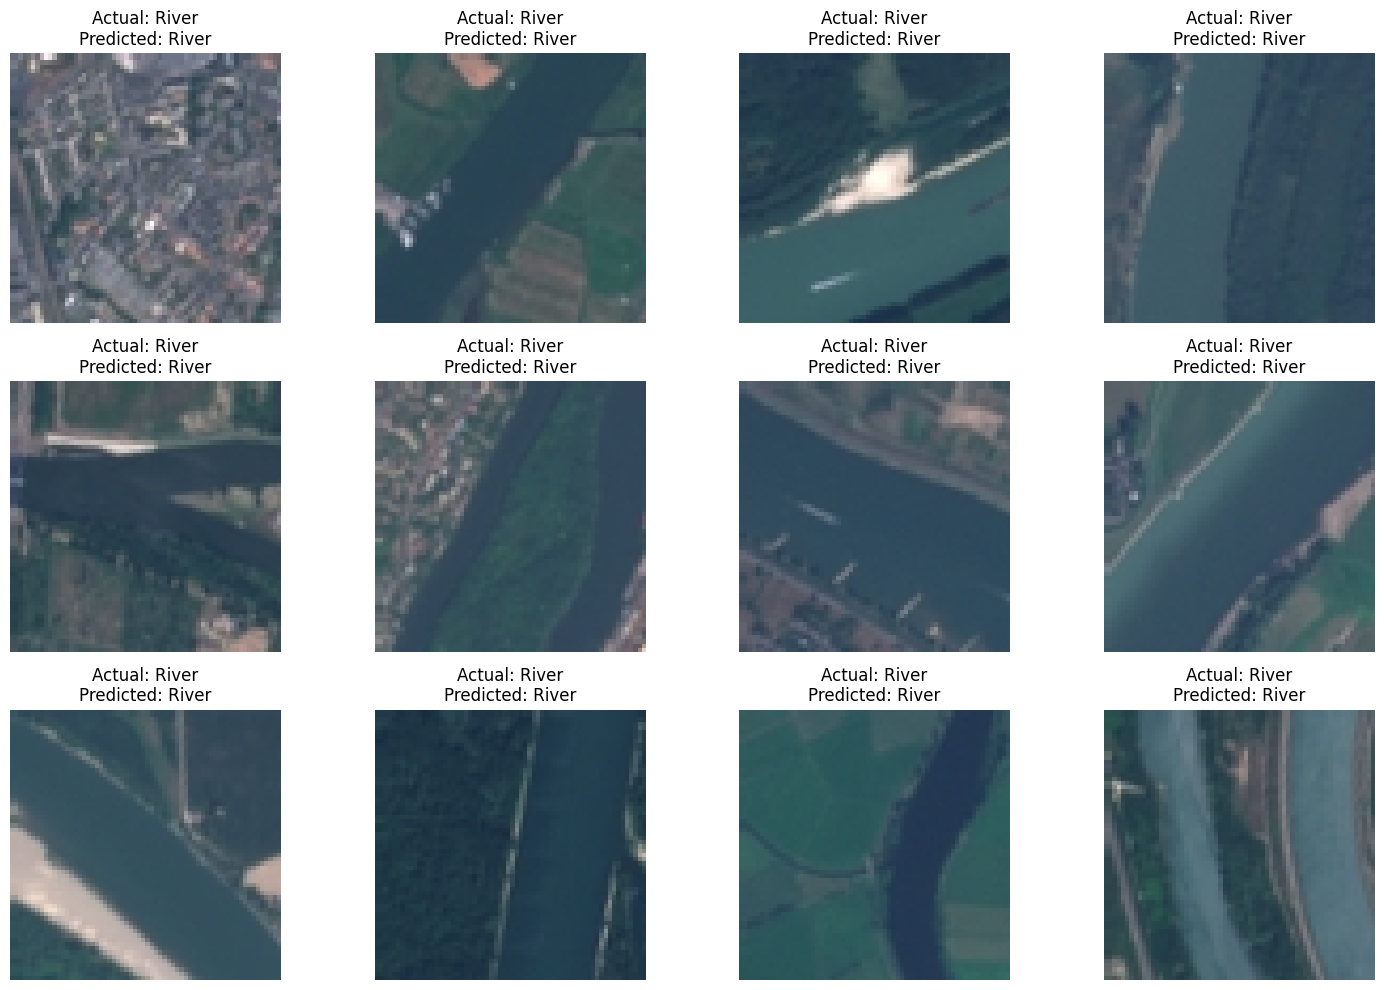

In [49]:
plt.figure(figsize=(15, 10))

for i in range(min(12, len(correct_river_indices))):

    image, label = val_dataset[idx]

    image = image.permute(1,2,0)

    idx = correct_river_indices[i]

    actual = class_names[all_labels[idx]]
    predicted = class_names[all_predictions[idx]]

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

for i in range(min(12, len(correct_river_indices))):

this part we might get a question why not use

for i in range(12):

because if we have less number of correct images say 7 then there will be an index issue so we are checking the minimum so that any number correct images present, we will get no index error.

Calculating the brightness for the correctly classified river images

In [50]:
correct_river_brightness = []

for idx in correct_river_indices:

    image, label = val_dataset[idx]

    brightness = image.mean().item()

    correct_river_brightness.append(brightness)

In [51]:
print(len(correct_river_brightness))

291


In [52]:
average_correct_river_brightness = sum(correct_river_brightness) / len(correct_river_brightness)
print(average_correct_river_brightness)

0.31617769998373446


In [53]:
average_misclassified_brightness

0.33865750758420854

/tmp/ipykernel_740/2979784007.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


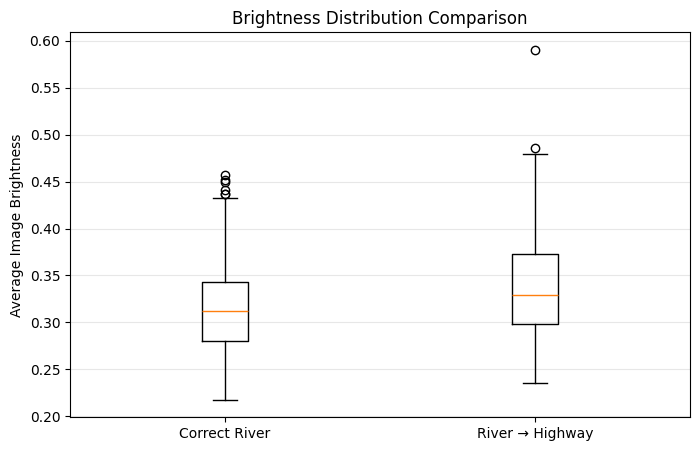

In [54]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [correct_river_brightness, misclassified_brightness],
    labels=["Correct River", "River → Highway"]
)

plt.ylabel("Average Image Brightness")
plt.title("Brightness Distribution Comparison")
plt.grid(axis="y", alpha=0.3)

plt.show()

Trying image segmentaion to know more about the image features(HSV format)

In [55]:
rgb = image.permute(1,2,0).cpu().numpy()

This changes the image from PyTorch's CHW format to NumPy's HWC format.

In [56]:
from matplotlib.colors import rgb_to_hsv

hsv = rgb_to_hsv(rgb)

print(hsv.shape)

(64, 64, 3)


same 3 channels but different values(Hue, Saturation, Value)

 The Hue is the color of the image, the Saturation is the pureness of the hue color, and the value is the strength of the hue.


 Here in this case :

 Hue: Helps distinguish colour types, such as blue water and green vegetation.

Saturation: Helps distinguish vivid colours from greyish or less saturated regions.

Value: Represents brightness.


Visualize the HSV channels

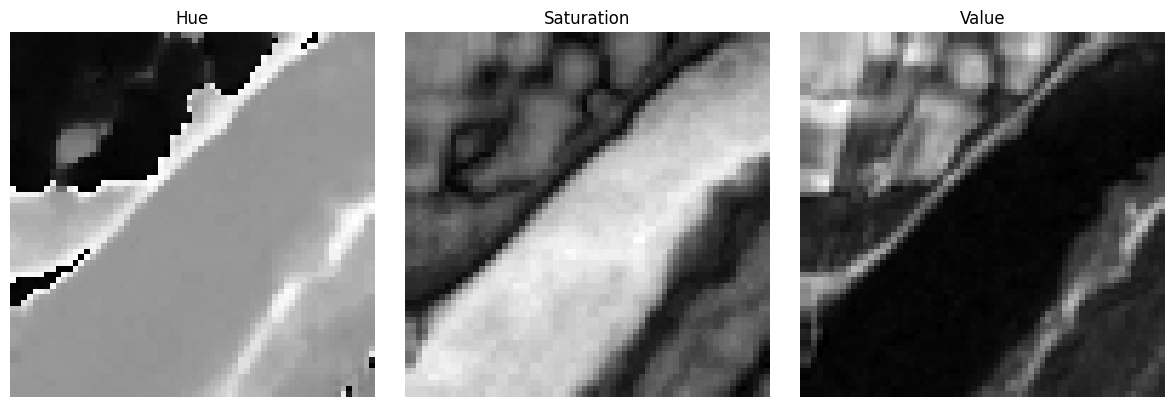

In [57]:
plt.figure(figsize=(12,4))

channel_names = ["Hue","Saturation","Value"]

for i in range(3):
  plt.subplot(1,3,i+1)
  plt.imshow(hsv[:, :, i], cmap="gray")
  plt.title(channel_names[i])
  plt.axis("off")

plt.tight_layout()
plt.show()

In [58]:
river_hsv = hsv[10:30, 10:25, :]
land_hsv = hsv[30:60, 40:55]



Calculate the average HSV values of land and river

In [59]:
river_hsv_mean = river_hsv.mean(axis=(0,1))
land_hsv_mean = land_hsv.mean(axis=(0,1))


print("River HSV: ",river_hsv_mean)
print("Land HSV: ",land_hsv_mean)

River HSV:  [0.22679336 0.14371894 0.5248228 ]
Land HSV:  [0.67146313 0.24310933 0.39248738]


Displaying the river and land parts in the original RGB format

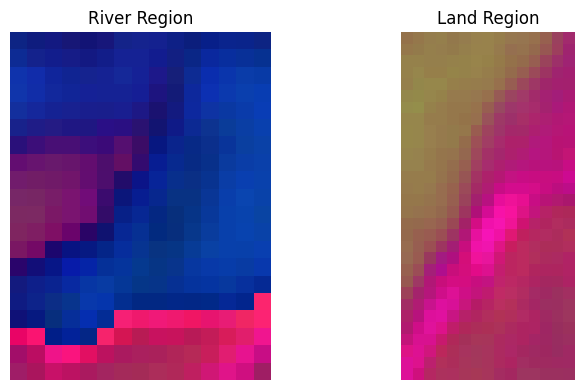

In [60]:
plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.imshow(rgb_to_hsv(rgb)[10:30, 10:25])
plt.title("River Region")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(rgb_to_hsv(rgb)[30:60, 40:55])
plt.title("Land Region")
plt.axis("off")


plt.tight_layout()
plt.show()

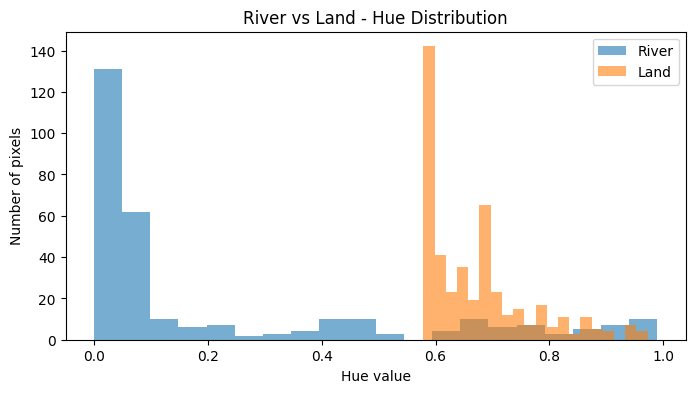

In [61]:
river_hue = river_hsv[:,:,0]
land_hue = land_hsv[:,:,0]


plt.figure(figsize=(8,4))

plt.hist(river_hue.flatten(),bins=20,alpha=0.6,label="River")
plt.hist(land_hue.flatten(),bins=20,alpha=0.6,label="Land")

plt.xlabel("Hue value")
plt.ylabel("Number of pixels")
plt.title("River vs Land - Hue Distribution")
plt.legend()
plt.show()

Working with a new image

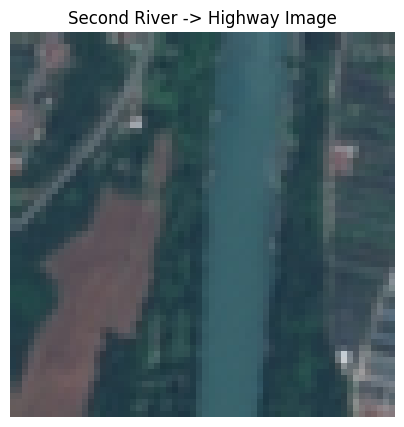

In [62]:
idx = river_highway_indices[1]
image, label = val_dataset[idx]

rgb = image.permute(1,2,0).cpu().numpy()

hsv = rgb_to_hsv(rgb)

plt.figure(figsize=(5,5))
plt.imshow(rgb)
plt.title("Second River -> Highway Image")
plt.axis("off")
plt.show()


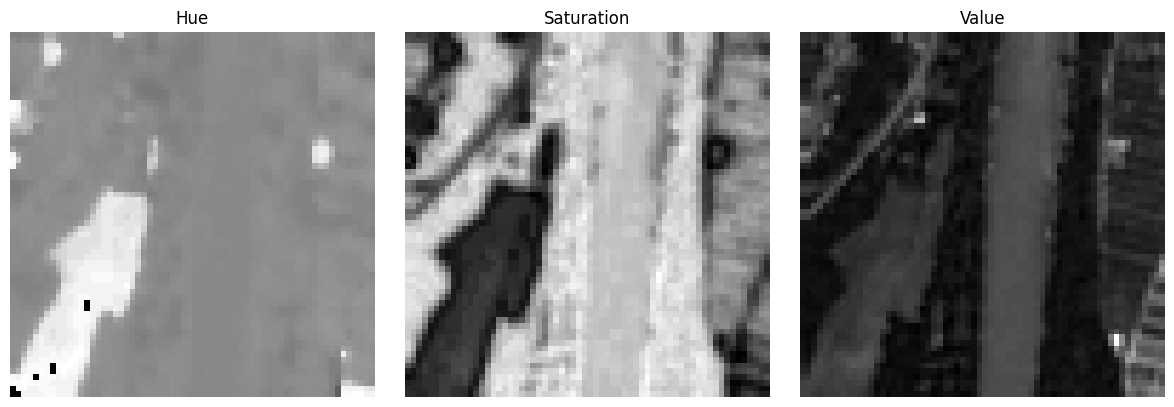

In [63]:
plt.figure(figsize=(12,4))

channel_names = ["Hue","Saturation","Value"]

for i in range(3):
  plt.subplot(1,3,i+1)
  plt.imshow(hsv[:, :, i], cmap="gray")
  plt.title(channel_names[i])
  plt.axis("off")

plt.tight_layout()
plt.show()

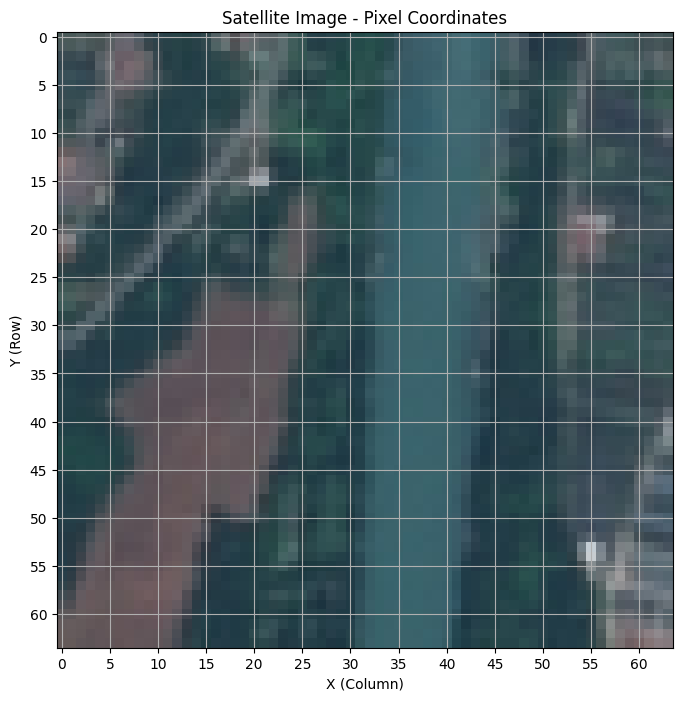

In [64]:
plt.figure(figsize=(8, 8))

plt.imshow(image.permute(1, 2, 0))

plt.xticks(range(0, 64, 5))
plt.yticks(range(0, 64, 5))

plt.grid()
plt.xlabel("X (Column)")
plt.ylabel("Y (Row)")
plt.title("Satellite Image - Pixel Coordinates")

plt.show()

In [65]:
river_hsv_2 = hsv[10:25, 33:41, :]
land_hsv_2 = hsv[32:45, 5:18,:]

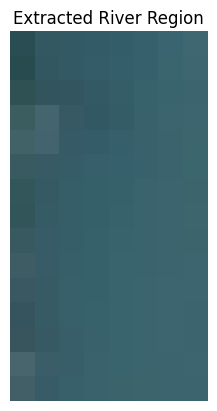

In [66]:
river_hsv_2_image = image[:,10:25, 33:41]
plt.imshow(river_hsv_2_image.permute(1, 2, 0))
plt.title("Extracted River Region")
plt.axis("off")
plt.show()

In [67]:
print(river_hsv_2.shape)
print(land_hsv_2.shape)

(15, 8, 3)
(13, 13, 3)


In [68]:
river_hsv_2_mean = river_hsv_2.mean(axis=(0,1))
land_hsv_2_mean = land_hsv_2.mean(axis=(0,1))


print("River HSV: ",river_hsv_2_mean)
print("Land HSV: ",land_hsv_2_mean)

River HSV:  [0.5326838  0.46027708 0.41120937]
Land HSV:  [0.7747345  0.18706594 0.34398434]


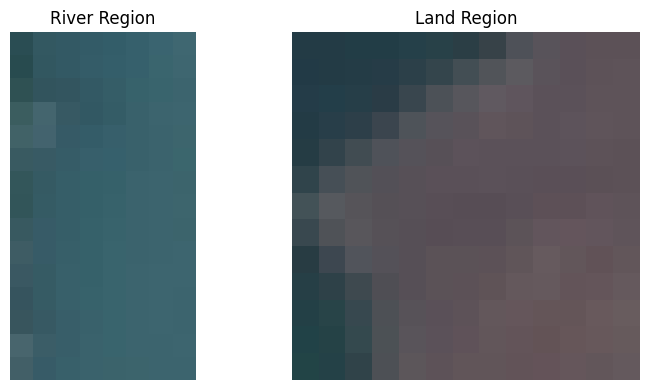

In [69]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(rgb[10:25, 33:41])
plt.title("River Region")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rgb[32:45, 5:18])
plt.title("Land Region")
plt.axis("off")

plt.tight_layout()
plt.show()

In [70]:
river_hue_2 = river_hsv_2[:, :, 0]
land_hue_2 = land_hsv_2[:, :, 0]

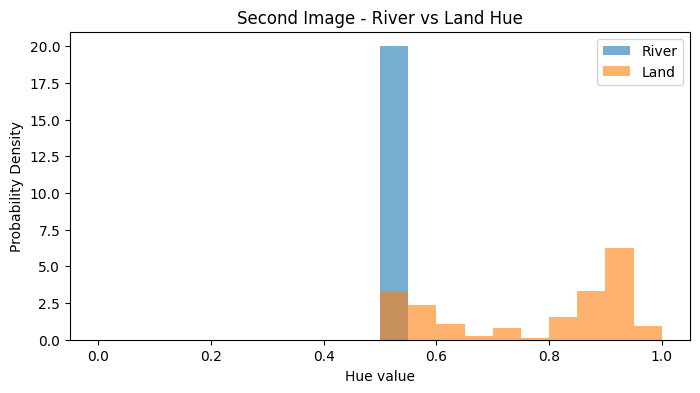

In [71]:
import numpy as np

bins = np.linspace(0, 1, 21)

plt.figure(figsize=(8, 4))

plt.hist(river_hue_2.flatten(), bins=bins, density=True, alpha=0.6, label="River")
plt.hist(land_hue_2.flatten(), bins=bins, density=True, alpha=0.6, label="Land")

plt.xlabel("Hue value")
plt.ylabel("Probability Density")
plt.title("Second Image - River vs Land Hue")
plt.legend()
plt.show()

In [72]:
print("River pixels:", river_hue_2.size)
print("Land pixels:", land_hue_2.size)

print("River Hue min:", river_hue_2.min())
print("River Hue max:", river_hue_2.max())

print("Land Hue min:", land_hue_2.min())
print("Land Hue max:", land_hue_2.max())

River pixels: 120
Land pixels: 169
River Hue min: 0.5092593
River Hue max: 0.5426357
Land Hue min: 0.5092593
Land Hue max: 0.9722222


Extracting the hue channel

In [73]:
hue_channel = hsv[:, :, 0]

In [74]:
print(hue_channel.shape)

(64, 64)


In [75]:
water_mask = (hue_channel > 0.50) & (hue_channel < 0.55)

In [76]:
water_mask.shape

(64, 64)

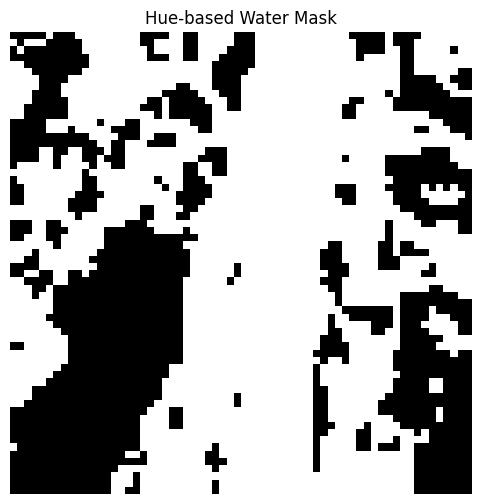

In [77]:
plt.figure(figsize=(6, 6))

plt.imshow(water_mask, cmap="gray")

plt.title("Hue-based Water Mask")
plt.axis("off")

plt.show()

Extracting the saturation channel

In [78]:
saturation_channel = hsv[:, :, 1]

In [79]:
print(saturation_channel.shape)

(64, 64)


In [80]:
river_sat_2 = river_hsv_2[:, :, 1]
land_sat_2 = land_hsv_2[:, :, 1]

In [81]:
print("River saturation:", river_sat_2.min(), river_sat_2.max())
print("Land saturation:", land_sat_2.min(), land_sat_2.max())

River saturation: 0.33944952 0.5142857
Land saturation: 0.052631576 0.53521127


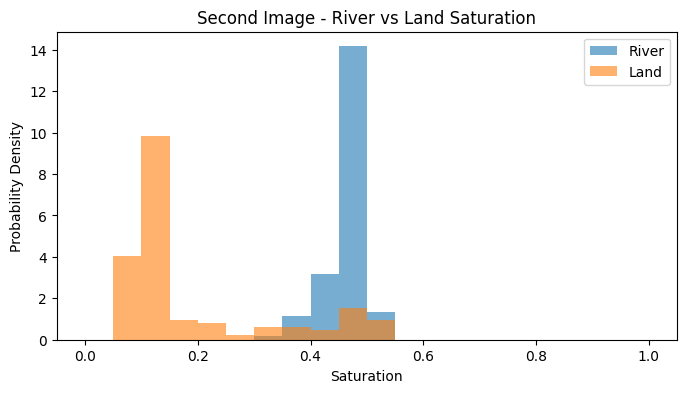

In [82]:
bins = np.linspace(0, 1, 21)

plt.figure(figsize=(8, 4))

plt.hist(river_sat_2.flatten(), bins=bins,
         density=True, alpha=0.6, label="River")

plt.hist(land_sat_2.flatten(), bins=bins,
         density=True, alpha=0.6, label="Land")

plt.xlabel("Saturation")
plt.ylabel("Probability Density")
plt.title("Second Image - River vs Land Saturation")
plt.legend()
plt.show()

In [83]:
water_mask_new = (hue_channel > 0.50) & (hue_channel < 0.55) & (saturation_channel > 0.40) & (saturation_channel < 0.50)

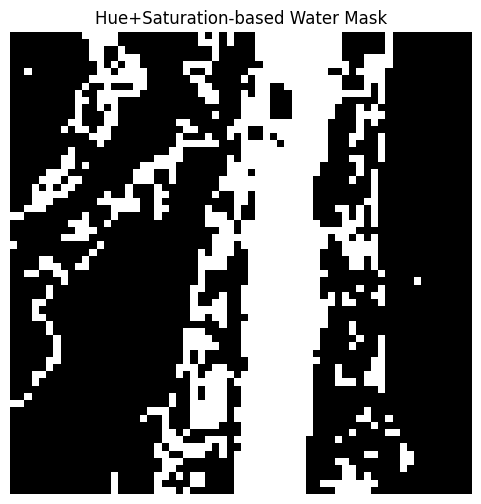

In [84]:
plt.figure(figsize=(6, 6))

plt.imshow(water_mask_new, cmap="gray")

plt.title("Hue+Saturation-based Water Mask")
plt.axis("off")

plt.show()

In [85]:
print("Hue condition:", ((hue_channel > 0.50) & (hue_channel < 0.55)).sum())

print("Saturation condition:", ((saturation_channel > 0.40) & (saturation_channel < 0.50)).sum())

print("Combined condition:", water_mask_new.sum())

Hue condition: 2562
Saturation condition: 1415
Combined condition: 1244


In [86]:
print("Hue range:", hue_channel.min(), hue_channel.max())
print("Saturation range:", saturation_channel.min(), saturation_channel.max())

Hue range: 0.0 0.9895833
Saturation range: 0.012738852 0.6


In [87]:
print("HSV shape:", hsv.shape)
print("Hue shape:", hue_channel.shape)
print("Saturation shape:", saturation_channel.shape)

print("Hue channel matches HSV:",
      np.allclose(hue_channel, hsv[:, :, 0]))

print("Saturation channel matches HSV:",
      np.allclose(saturation_channel, hsv[:, :, 1]))

HSV shape: (64, 64, 3)
Hue shape: (64, 64)
Saturation shape: (64, 64)
Hue channel matches HSV: True
Saturation channel matches HSV: True


In [88]:
hue_channel = hsv[:, :, 0]
saturation_channel = hsv[:, :, 1]

print(np.allclose(hue_channel, hsv[:, :, 0]))
print(np.allclose(saturation_channel, hsv[:, :, 1]))

True
True


There was some error in the previous mask so a new mask is made

In [89]:
water_mask_new = (
    (hue_channel > 0.50) &
    (hue_channel < 0.55) &
    (saturation_channel > 0.40) &
    (saturation_channel < 0.50)
)

print("Selected pixels:", water_mask_new.sum())

Selected pixels: 1244


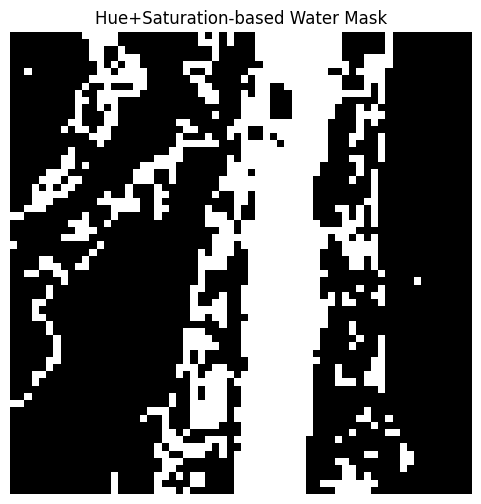

In [90]:
plt.figure(figsize=(6, 6))

plt.imshow(water_mask_new, cmap="gray")

plt.title("Hue+Saturation-based Water Mask")
plt.axis("off")

plt.show()

Overlaying the mask on the original image

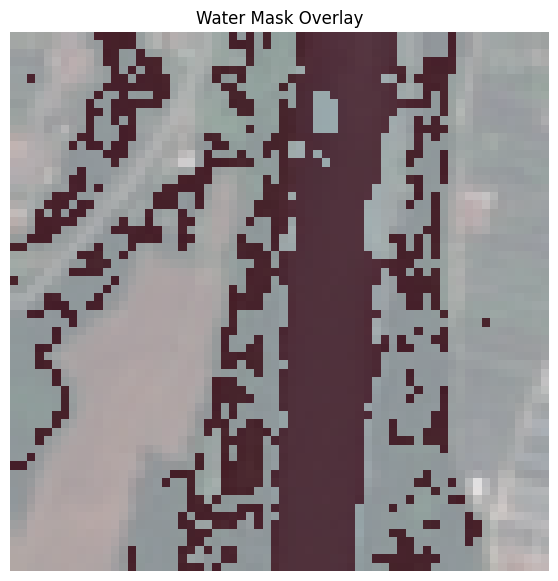

In [91]:
plt.figure(figsize=(7, 7))

plt.imshow(rgb)
plt.imshow(water_mask_new, cmap="Reds", alpha=0.5)

plt.title("Water Mask Overlay")
plt.axis("off")
plt.show()

In the above image, we can see the mask on the actual image. But we can't work on that because some part of the vegetation is also identified as the same pixels of the river. So we are going to implement a new technique used in Computer Vision i.e. CCA (Connected Component Analysis).

Implementing CCA (Connected Component Analysis).

In [92]:
import cv2

In [93]:
cv2.__version__

'5.0.0'

In [94]:
water_mask_uint8 = water_mask_new.astype("uint8")

Reason for water mask conversion : Because OpenCV expects binary image values represented as integers, conventionally 0 and 255 (or 0 and 1 for connected-component analysis).

In [95]:
print(water_mask_uint8.dtype)
print(water_mask_uint8.shape)
print(water_mask_uint8.min(), water_mask_uint8.max())

uint8
(64, 64)
0 1


In [96]:
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    water_mask_uint8,connectivity=8
)

In [97]:
print("Number of labels:", num_labels)
print("Labels shape:", labels.shape)
print("Stats shape:", stats.shape)
print("Centroids shape:", centroids.shape)

Number of labels: 35
Labels shape: (64, 64)
Stats shape: (35, 5)
Centroids shape: (35, 2)


Inspecting the components

In [98]:
for i in range(1, num_labels):

    area = stats[i,4]

    print("Component:", i, "Area:", area)

Component: 1 Area: 70
Component: 2 Area: 22
Component: 3 Area: 2
Component: 4 Area: 930
Component: 5 Area: 1
Component: 6 Area: 1
Component: 7 Area: 53
Component: 8 Area: 4
Component: 9 Area: 30
Component: 10 Area: 5
Component: 11 Area: 1
Component: 12 Area: 11
Component: 13 Area: 1
Component: 14 Area: 5
Component: 15 Area: 10
Component: 16 Area: 18
Component: 17 Area: 1
Component: 18 Area: 4
Component: 19 Area: 1
Component: 20 Area: 3
Component: 21 Area: 4
Component: 22 Area: 14
Component: 23 Area: 5
Component: 24 Area: 3
Component: 25 Area: 4
Component: 26 Area: 1
Component: 27 Area: 1
Component: 28 Area: 2
Component: 29 Area: 1
Component: 30 Area: 6
Component: 31 Area: 20
Component: 32 Area: 2
Component: 33 Area: 3
Component: 34 Area: 5


In [99]:
component_areas = []
for i in range(1,num_labels):
  area = int(stats[i,4])
  component_areas.append((i,area))

component_areas.sort(key=lambda x:x[1], reverse=True)

print(component_areas[:10])

[(4, 930), (1, 70), (7, 53), (9, 30), (2, 22), (31, 20), (16, 18), (22, 14), (12, 11), (15, 10)]


the sorting part :

key=lambda x: x[1]

means that sorting should be based on the second element of each tuple (the area), not the component ID.

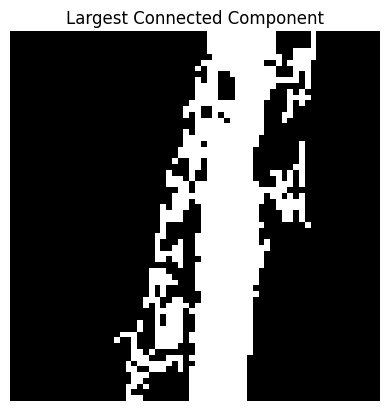

In [100]:
largest_component_mask = (labels == 4)

plt.imshow(largest_component_mask, cmap="gray")
plt.title("Largest Connected Component")
plt.axis("off")
plt.show()

Overlaying the Largest Connected Component on the actual image

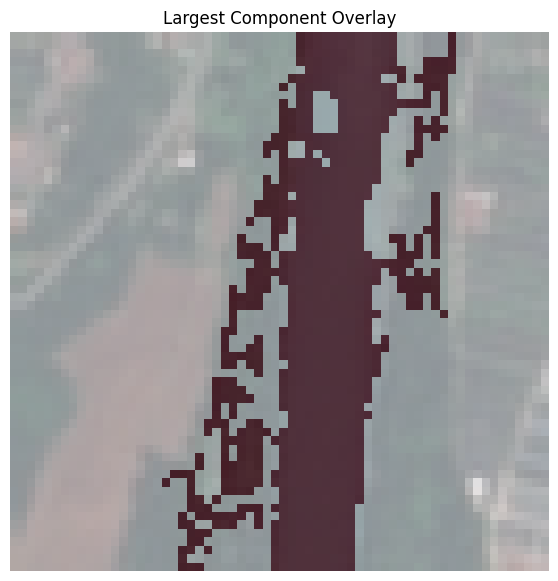

In [101]:
plt.figure(figsize=(7, 7))

plt.imshow(rgb)
plt.imshow(largest_component_mask, cmap="Reds", alpha=0.5)

plt.title("Largest Component Overlay")
plt.axis("off")
plt.show()

In [102]:
component_id = 4

left = stats[component_id, 0]
top = stats[component_id, 1]

width = stats[component_id, 2]
height = stats[component_id, 3]

area = stats[component_id, 4]

In [103]:
print("Left: ",left)
print("Top: ",top)
print("Width: ",width)
print("Height: ",height)
print("Area: ",area)

Left:  18
Top:  0
Width:  35
Height:  64
Area:  930


Calculating the aspect ratio

How will we interpret it?
- Greater than 1 → Taller than it is wide.
- Less than 1 → Wider than it is tall.
- Approximately 1 → Similar height and width.

In [104]:
aspect_ratio = height / width

print("Aspect Ratio:", aspect_ratio)

Aspect Ratio: 1.8285714285714285


In [105]:
bounding_box_area = width * height

extent = area / bounding_box_area

print("Extent:", extent)

Extent: 0.41517857142857145


Extent measures how much of the bounding box is occupied by the component.

Here, it means Component 4 occupies approximately 41.52% of its bounding box.

In [106]:
component_mask = (labels == 4).astype("uint8")

contours, heirarchy = cv2.findContours(
    component_mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE
)

Description of each part :

labels == 4: Selects only Component 4.



astype("uint8"): Converts it to the format OpenCV expects.



findContours(): Finds the boundaries of the selected region.



RETR_EXTERNAL: Retrieves only the outermost contours.



CHAIN_APPROX_SIMPLE: Compresses redundant contour points.

In [107]:
print("Number of contours: ",len(contours))

Number of contours:  1


Calculating the Hull Area

In [108]:
hull = cv2.convexHull(contours[0])

hull_area = cv2.contourArea(hull)

Explanation:
- contours[0] selects our first (and only) contour.
- cv2.convexHull() finds the smallest convex shape enclosing it.
- cv2.contourArea() calculates the area enclosed by that hull.

In [110]:
solidity = area / hull_area
print("Comvex Hull Area: ",hull_area)
print("Solidity: ",solidity)

Comvex Hull Area:  1503.5
Solidity:  0.6185567010309279


Interpretation from Solidity:

This means Component 4 occupies approximately 61.86% of its convex hull.

TESTING THE ANALYSIS WITH ANOTHER IMAGE FROM THE SAME RIVER-HIGHWAY MISCLASSIFIED IMAGES

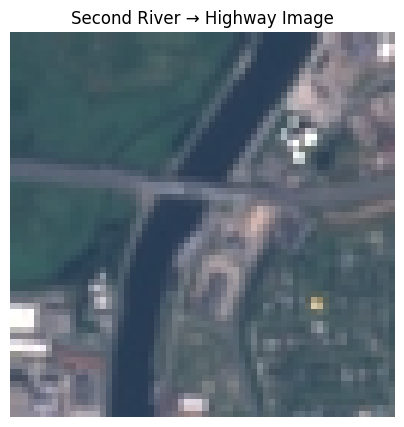

In [111]:
idx = river_highway_indices[2]

image, label = val_dataset[idx]

rgb = image.permute(1, 2, 0).cpu().numpy()
hsv = rgb_to_hsv(rgb)

plt.figure(figsize=(5, 5))
plt.imshow(rgb)
plt.title("Second River → Highway Image")
plt.axis("off")
plt.show()

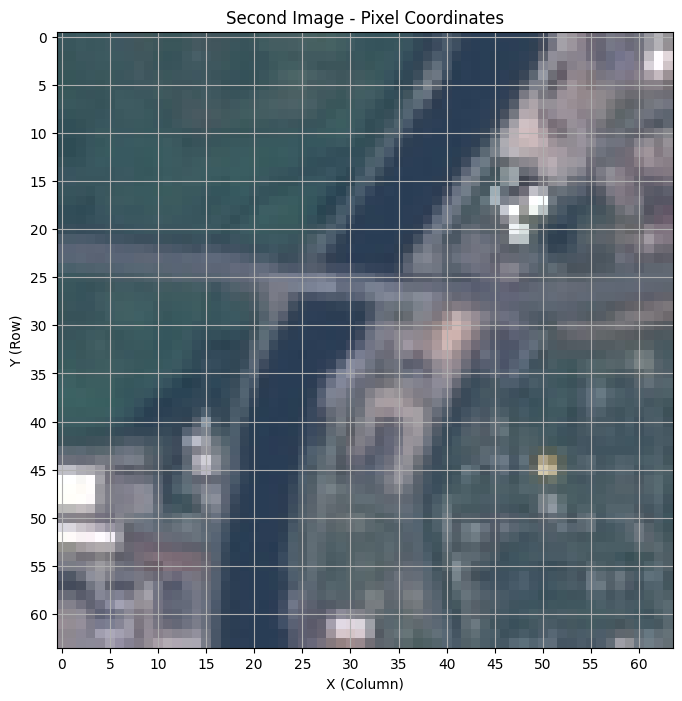

In [112]:
plt.figure(figsize=(8, 8))

plt.imshow(rgb)

plt.xticks(range(0, 64, 5))
plt.yticks(range(0, 64, 5))

plt.grid()
plt.xlabel("X (Column)")
plt.ylabel("Y (Row)")
plt.title("Second Image - Pixel Coordinates")

plt.show()

In [113]:
river_region_1 = hsv[10:18, 32:37, :]
river_region_2 = hsv[35:43, 19:24, :]

vegetation_region_1 = hsv[5:15, 3:13, :]
vegetation_region_2 = hsv[50:60, 45:55, :]

other_land_region = hsv[5:15, 55:62, :]


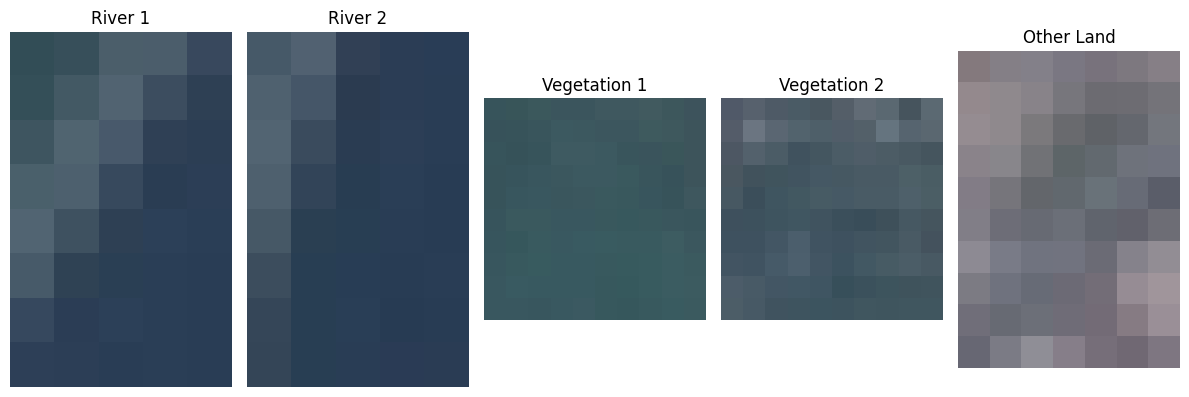

In [114]:
from matplotlib.colors import hsv_to_rgb
plt.figure(figsize=(12, 7))

regions = [
    (river_region_1, "River 1"),
    (river_region_2, "River 2"),
    (vegetation_region_1, "Vegetation 1"),
    (vegetation_region_2, "Vegetation 2"),
    (other_land_region, "Other Land")
]

for i, (region, name) in enumerate(regions):
    plt.subplot(1, 5, i+1)
    plt.imshow(hsv_to_rgb(region))
    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [115]:
river_1_mean = river_region_1.mean(axis=(0, 1))
river_2_mean = river_region_2.mean(axis=(0, 1))

vegetation_1_mean = vegetation_region_1.mean(axis=(0, 1))
vegetation_2_mean = vegetation_region_2.mean(axis=(0, 1))

other_land_mean = other_land_region.mean(axis=(0, 1))

In [116]:
print("River 1:", river_1_mean)
print("River 2:", river_2_mean)

print("Vegetation 1:", vegetation_1_mean)
print("Vegetation 2:", vegetation_2_mean)

print("Other Land:", other_land_mean)

River 1: [0.57967305 0.42104912 0.3631372 ]
River 2: [0.58693707 0.45692277 0.3492156 ]
Vegetation 1: [0.5282066  0.38330823 0.3676863 ]
Vegetation 2: [0.5632601  0.28805065 0.39141154]
Other Land: [0.71360326 0.08041296 0.4942858 ]


In [117]:
import numpy as np

regions = {
    "River 1": river_region_1,
    "River 2": river_region_2,
    "Vegetation 1": vegetation_region_1,
    "Vegetation 2": vegetation_region_2,
    "Other Land": other_land_region
}

for name, region in regions.items():

    print("\n", name)

    print("Minimum:", region.min(axis=(0, 1)))
    print("Maximum:", region.max(axis=(0, 1)))
    print("Standard deviation:", region.std(axis=(0, 1)))


 River 1
Minimum: [0.5416667 0.2767857 0.3254902]
Maximum: [0.5952381  0.517647   0.44705883]
Standard deviation: [0.01601876 0.08260354 0.03827097]

 River 2
Minimum: [0.5729167  0.28070173 0.3137255 ]
Maximum: [0.6007752  0.5301205  0.44705883]
Standard deviation: [0.00704115 0.08321566 0.03674523]

 Vegetation 1
Minimum: [0.517094   0.31578946 0.34901962]
Maximum: [0.5430108  0.41935486 0.38039216]
Standard deviation: [0.00583129 0.02535832 0.00801997]

 Vegetation 2
Minimum: [0.5430108  0.17054267 0.34901962]
Maximum: [0.6041667  0.37777779 0.5058824 ]
Standard deviation: [0.01213883 0.04986909 0.02781106]

 Other Land
Minimum: [0.54545456 0.02419355 0.40392157]
Maximum: [0.939394   0.14285713 0.627451  ]
Standard deviation: [0.09866194 0.02688118 0.05158631]


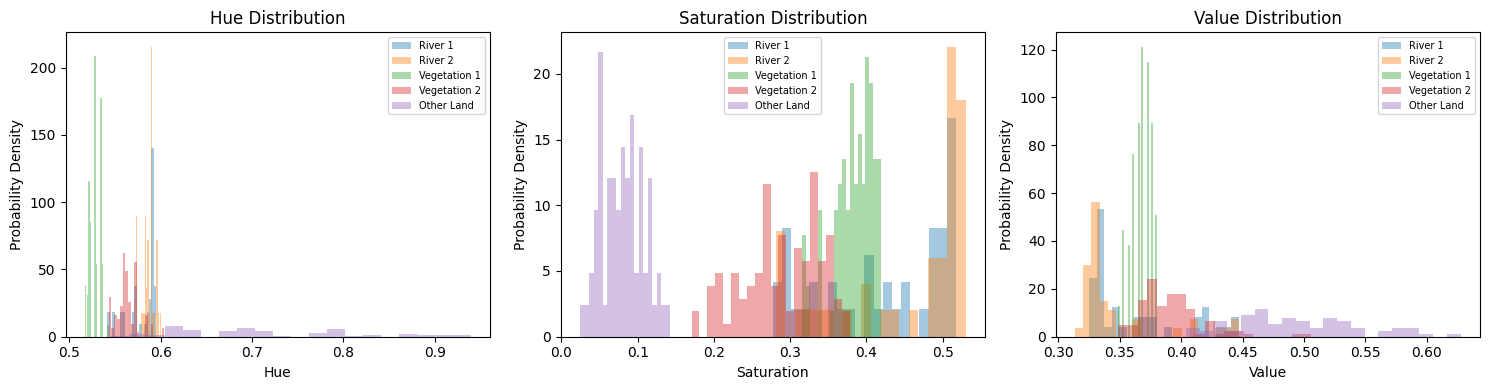

In [118]:
channel_names = ["Hue", "Saturation", "Value"]

plt.figure(figsize=(15, 4))

for i in range(3):

    plt.subplot(1, 3, i+1)

    for name, region in regions.items():

        plt.hist(
            region[:, :, i].flatten(),
            bins=20,
            density=True,
            alpha=0.4,
            label=name
        )

    plt.xlabel(channel_names[i])
    plt.ylabel("Probability Density")
    plt.title(channel_names[i] + " Distribution")
    plt.legend(fontsize=7)

plt.tight_layout()
plt.show()

In [119]:
hue_min = 0.54
hue_max = 0.61

sat_min = 0.28
sat_max = 0.54

In [120]:
def evaluate_region(region):

    hue = region[:, :, 0]
    saturation = region[:, :, 1]

    mask = (
        (hue >= hue_min) &
        (hue <= hue_max) &
        (saturation >= sat_min) &
        (saturation <= sat_max)
    )

    selected_pixels = mask.sum()
    total_pixels = mask.size

    selection_rate = (selected_pixels / total_pixels) * 100

    return selected_pixels, total_pixels, selection_rate

In [121]:
regions = {
    "River 1": river_region_1,
    "River 2": river_region_2,
    "Vegetation 1": vegetation_region_1,
    "Vegetation 2": vegetation_region_2,
    "Other Land": other_land_region
}

for name, region in regions.items():

    selected, total, rate = evaluate_region(region)

    print(f"\n{name}")
    print("Selected pixels:", selected)
    print("Total pixels:", total)
    print("Selection rate:", round(rate, 2), "%")


River 1
Selected pixels: 39
Total pixels: 40
Selection rate: 97.5 %

River 2
Selected pixels: 40
Total pixels: 40
Selection rate: 100.0 %

Vegetation 1
Selected pixels: 1
Total pixels: 100
Selection rate: 1.0 %

Vegetation 2
Selected pixels: 55
Total pixels: 100
Selection rate: 55.0 %

Other Land
Selected pixels: 0
Total pixels: 70
Selection rate: 0.0 %


In [127]:
hue_channel_new = hsv[:, :, 0]
saturation_channel_new = hsv[:, :, 1]

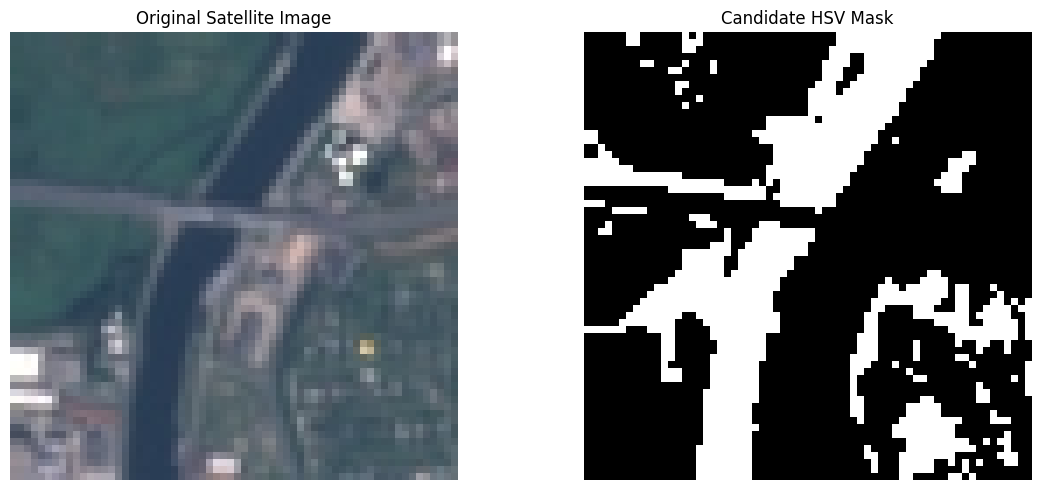

In [128]:
water_mask_test = (
    (hue_channel_new >= hue_min) &
    (hue_channel_new <= hue_max) &
    (saturation_channel_new >= sat_min) &
    (saturation_channel_new <= sat_max)
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("Original Satellite Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(water_mask_test, cmap="gray")
plt.title("Candidate HSV Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [129]:
mask_uint8 = water_mask_test.astype("uint8")

In [131]:
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    mask_uint8,
    connectivity=8
)

print("Total labels:", num_labels)
print("Foreground components:", num_labels - 1)

Total labels: 32
Foreground components: 31


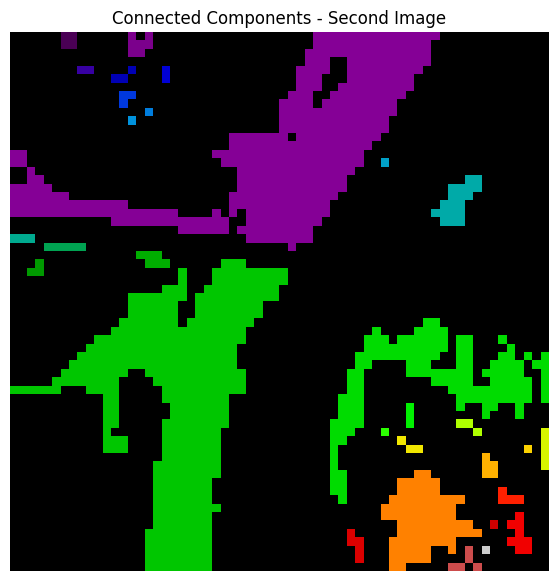

In [132]:
plt.figure(figsize=(7, 7))

plt.imshow(labels, cmap="nipy_spectral")

plt.title("Connected Components - Second Image")
plt.axis("off")

plt.show()

In [133]:
component_areas = []

for i in range(1, num_labels):

    area = int(stats[i, 4])
    component_areas.append((i, area))

component_areas.sort(key=lambda x: x[1], reverse=True)

print("Five largest components:", component_areas[:5])

Five largest components: [(16, 417), (3, 404), (17, 147), (25, 79), (11, 19)]


In [134]:
for component_id, component_area in component_areas[:5]:

    left = stats[component_id, 0]
    top = stats[component_id, 1]
    width = stats[component_id, 2]
    height = stats[component_id, 3]

    print(
        f"Component {component_id}: "
        f"Area={component_area}, "
        f"Left={left}, Top={top}, "
        f"Width={width}, Height={height}"
    )

Component 16: Area=417, Left=0, Top=27, Width=33, Height=37
Component 3: Area=404, Left=0, Top=0, Width=51, Height=26
Component 17: Area=147, Left=38, Top=34, Width=26, Height=22
Component 25: Area=79, Left=44, Top=52, Width=12, Height=12
Component 11: Area=19, Left=50, Top=17, Width=6, Height=6


Here in this image we can see the river be divided into 2 parts because of the presence of a bridge in the horizonal axis.